# Analysis of baseline activity type fits

Multinomial (softmax) regression of the number of vessels of each activity type per rat. Coefficients are log-odds relative to the reference category `canonical`; below we convert them to fractions for a typical rat (i.e. with rat effect zero).

In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim, plot_ppc_multinomial
from kidney.sign_probs import get_sign_probs, get_signif

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"
PLOT_DIR_NEW.mkdir(exist_ok=True)

In [3]:
CATEGORIES = ["canonical", "double", "subthreshold", "beats"]
YCOL = f"c({', '.join(CATEGORIES)})"
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_activity_types_vehicle.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_activity_types_empa.nc")
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["baseline_activity_types_vehicle"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["baseline_activity_types_empa"])

In [4]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~p", "~1|rat"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~p", "~1|rat"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept[double],-2.040,0.713,-3.516,-0.841,0.015,0.011,2233.0,2656.0,1.0
Intercept[subthreshold],-4.132,1.049,-5.990,-2.070,0.018,0.015,3302.0,2752.0,1.0
Intercept[beats],-5.474,1.025,-7.450,-3.626,0.014,0.017,5172.0,3332.0,1.0
"gtyp[double, fa/fa]",-0.452,0.860,-1.988,1.210,0.015,0.013,3145.0,3071.0,1.0
"gtyp[subthreshold, fa/fa]",0.513,1.058,-1.482,2.460,0.016,0.015,4181.0,3353.0,1.0
"gtyp[beats, fa/fa]",1.980,0.984,0.151,3.834,0.014,0.017,4741.0,3062.0,1.0
"age[double, Young]",-0.625,0.872,-2.393,0.923,0.015,0.013,3511.0,2804.0,1.0
"age[subthreshold, Young]",-0.193,1.047,-2.124,1.788,0.018,0.016,3292.0,2909.0,1.0
"age[beats, Young]",-0.814,1.051,-2.802,1.162,0.014,0.018,5405.0,2882.0,1.0
"sex[double, M]",-1.101,0.818,-2.650,0.401,0.014,0.012,3285.0,2936.0,1.0


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept[double],-2.069,0.484,-3.003,-1.179,0.009,0.008,3137.0,2783.0,1.0
Intercept[subthreshold],-2.407,0.866,-3.996,-0.762,0.018,0.013,2312.0,2598.0,1.0
Intercept[beats],-5.547,1.076,-7.688,-3.728,0.017,0.018,4071.0,3162.0,1.0
"gtyp[double, fa/fa]",0.070,0.655,-1.140,1.288,0.011,0.010,3520.0,3198.0,1.0
"gtyp[subthreshold, fa/fa]",0.075,0.955,-1.778,1.795,0.017,0.014,3152.0,3060.0,1.0
"gtyp[beats, fa/fa]",1.528,0.989,-0.384,3.324,0.017,0.015,3426.0,2706.0,1.0
"age[double, Young]",-1.010,0.687,-2.250,0.353,0.011,0.011,3954.0,2724.0,1.0
"age[subthreshold, Young]",-0.016,0.935,-1.738,1.797,0.019,0.015,2353.0,2506.0,1.0
"age[beats, Young]",-0.515,1.071,-2.557,1.412,0.014,0.018,5971.0,2747.0,1.0
"sex[double, M]",-0.216,0.630,-1.427,0.947,0.011,0.010,3574.0,2848.0,1.0


## Posterior predictive checks

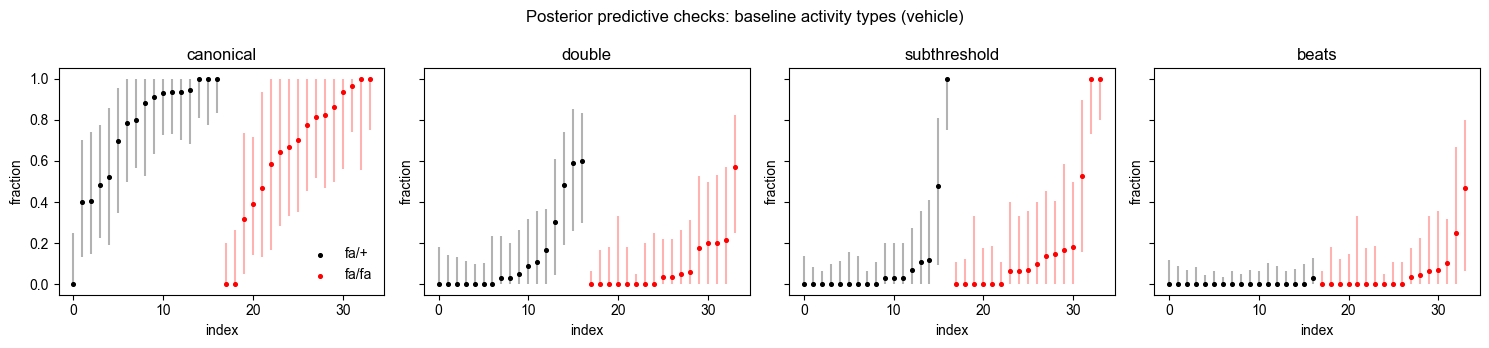

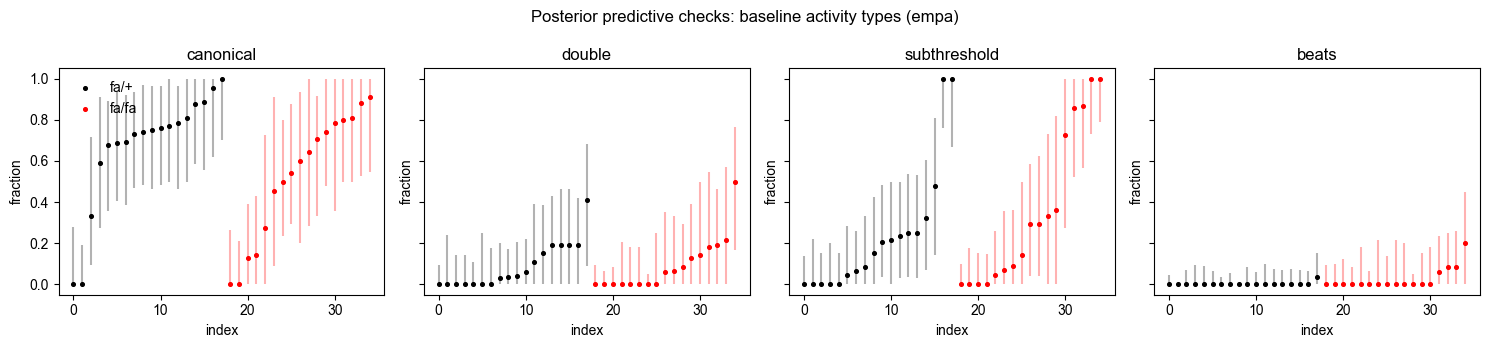

In [5]:
for idata, name, msts in zip(
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    f, axes = plt.subplots(1, 4, figsize=[15, 3.5], sharey=True)
    axes = plot_ppc_multinomial(axes, idata, msts, CATEGORIES, groupcol="gtyp", colors={"fa/+": "k", "fa/fa": "r"})
    f.suptitle(f"Posterior predictive checks: baseline activity types ({name})");
    f.tight_layout()
    f.savefig(PLOT_DIR_NEW / f"ppc_baseline_activity_types_{name}.png", bbox_inches="tight", dpi=200)

Each dot is a rat's observed fraction, sorted by genotype and fraction; lines are 1%-99% posterior predictive intervals.

Since many rats have zero vessels of some types, we also check the number of rats with no vessels of each type against its posterior predictive distribution.

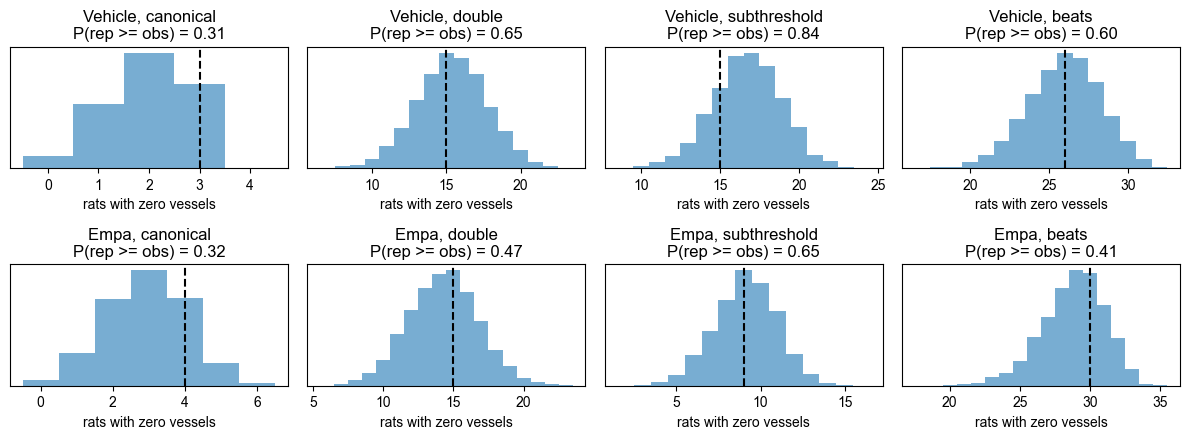

In [6]:
f, axes = plt.subplots(2, 4, figsize=[12, 4.5])
for ax_row, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("Vehicle", "Empa"),
    (msts_vehicle, msts_empa),
):
    n_zero_rep = (idata.posterior_predictive[YCOL] == 0).sum("__obs__")
    for ax, category in zip(ax_row, CATEGORIES):
        rep = n_zero_rep.sel({f"{YCOL}_dim": category}).to_numpy().ravel()
        obs = (msts[category] == 0).sum()
        ax.hist(rep, bins=np.arange(rep.min(), rep.max() + 2) - 0.5, color="tab:blue", alpha=0.6)
        ax.axvline(obs, color="black", linestyle="--")
        p_ge = (rep >= obs).mean()
        ax.set(title=f"{name}, {category}\nP(rep >= obs) = {p_ge:.2f}", xlabel="rats with zero vessels", yticks=[])
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_baseline_activity_types_zeros.png", bbox_inches="tight", dpi=200)

## Compute group fractions

In [7]:
REDUCED_DIM = f"{YCOL}_reduced_dim"


def softmax_with_reference(eta):
    eta = (
        eta.pad({REDUCED_DIM: (1, 0)}, constant_values=0)
        .rename({REDUCED_DIM: "activity_type"})
        .assign_coords(activity_type=CATEGORIES)
    )
    exp_eta = np.exp(eta)
    return exp_eta / exp_eta.sum("activity_type")


def get_group_fractions(idata):
    # get_t_groups leaves out the Intercept, which doesn't cancel after softmax
    return {
        k: softmax_with_reference(idata.posterior["Intercept"] + v)
        for k, v in get_t_groups(idata).items()
    }


t_groups_vehicle, t_groups_empa = (get_group_fractions(idata) for idata in (idata_vehicle, idata_empa))

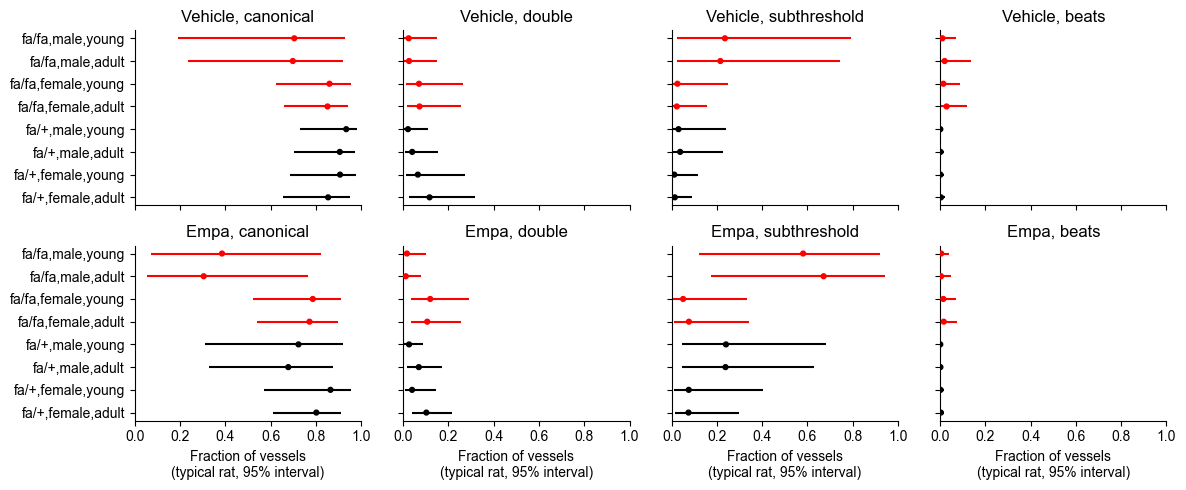

In [8]:
f, axes = plt.subplots(2, 4, figsize=[12, 5], sharex=True, sharey=True)
for ax_row, t_groups, name in zip(axes, (t_groups_vehicle, t_groups_empa), ("Vehicle", "Empa")):
    for ax, category in zip(ax_row, CATEGORIES):
        groups = list(t_groups.keys())
        qs = np.array([np.quantile(t_groups[g].sel(activity_type=category), [0.025, 0.5, 0.975]) for g in groups])
        ax.hlines(range(len(groups)), qs[:, 0], qs[:, 2], color=["r" if "fa/fa" in g else "k" for g in groups])
        ax.scatter(qs[:, 1], range(len(groups)), color=["r" if "fa/fa" in g else "k" for g in groups], s=12, zorder=10)
        ax.set_yticks(range(len(groups)), groups)
        ax.set(title=f"{name}, {category}", xlim=(0, 1))
        ax.spines[['top', 'right']].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("Fraction of vessels\n(typical rat, 95% interval)")
f.tight_layout()

## Overall effects on the fraction scale

As requested in the brief, we test the overall effects of gtyp, age and sex on the fraction of vessels of each activity type. Each effect is a difference in fraction, averaged with equal weights over the levels of the other factors. Because the fractions sum to 1, the four columns are not independent: each row's effects sum to zero across activity types. SP is the posterior probability that the effect is positive; lines are 95% intervals.

In [29]:
overall_vehicle, overall_empa = (
    get_overall_effects(t)
    for t in (t_groups_vehicle, t_groups_empa)
)

def sex_effect_by_gtyp(t_groups, gtyp):
    return sum(
        t_groups[f"{gtyp},male,{age}"]
        - t_groups[f"{gtyp},female,{age}"]
        for age in ("young", "adult")
    ) / 2


for overall, t_groups in zip(
    (overall_vehicle, overall_empa),
    (t_groups_vehicle, t_groups_empa),
):
    # Remove overall sex effect
    overall.pop("male - female")

    # Add genotype-specific sex effects
    for gtyp in ("fa/fa", "fa/+"):
        overall[f"male - female ({gtyp})"] = sex_effect_by_gtyp(
            t_groups, gtyp
        )

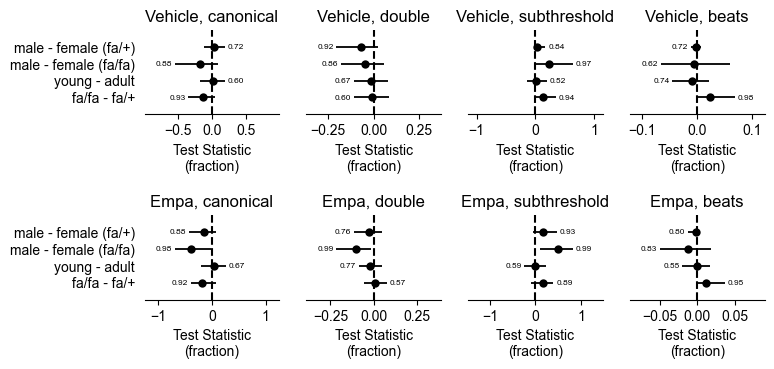

In [30]:
f, axes = plt.subplots(2, 4, figsize=(8, 3.5))
plt.subplots_adjust(hspace=1.2)

for ax_row, overall, name in zip(
    axes,
    (overall_vehicle, overall_empa),
    ("Vehicle", "Empa"),
):
    for ax, category in zip(ax_row, CATEGORIES):
        ts = {
            k: v.sel(activity_type=category)
            for k, v in overall.items()
        }

        forestplot_oz(
            ax, ts,
            xlabel="Test Statistic\n(fraction)",
            sign_probs=True,
        )
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(f"{name}, {category}")
        ax.spines[["top", "right", "left"]].set_visible(False)

    for ax in ax_row[1:]:
        ax.set_yticks([], [])


f.savefig(PLOT_DIR_NEW / "ts_baseline_activity_types_overall.png", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [28]:
def get_effects_with_sex_by_gtyp(t_groups):
    effects = get_overall_effects(t_groups)
    effects.pop("male - female", None)

    for gtyp in ("fa/fa", "fa/+"):
        effects[f"male - female ({gtyp})"] = sex_effect_by_gtyp(
            t_groups, gtyp
        )

    return effects


overall_vehicle = get_effects_with_sex_by_gtyp(t_groups_vehicle)
overall_empa = get_effects_with_sex_by_gtyp(t_groups_empa)

sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {
                k: get_signif(v)
                for k, v in get_sign_probs(ts_vehicle).items()
            },
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {
                k: get_signif(v)
                for k, v in get_sign_probs(ts_empa).items()
            },
        })
        for category in CATEGORIES
        for ts_vehicle, ts_empa in [(
            {k: v.sel(activity_type=category) for k, v in overall_vehicle.items()},
            {k: v.sel(activity_type=category) for k, v in overall_empa.items()},
        )]
    ],
    keys=CATEGORIES,
    names=("activity_type", "contrast"),
)

sp_all

vehicle vehicle_signif     empa  \
activity_type contrast                                                 
canonical     fa/fa - fa/+           0.06850                 0.07650   
              young - adult          0.60100                 0.66550   
              male - female (fa/fa)  0.12150                 0.02050   
              male - female (fa/+)   0.72500                 0.12350   
double        fa/fa - fa/+           0.39525                 0.56850   
              young - adult          0.32550                 0.23475   
              male - female (fa/fa)  0.14050                 0.01475   
              male - female (fa/+)   0.08000                 0.24225   
subthreshold  fa/fa - fa/+           0.93800                 0.89125   
              young - adult          0.52450                 0.40625   
              male - female (fa/fa)  0.96975                 0.99350   
              male - female (fa/+)   0.83525                 0.92725   
beats         fa/fa - fa/+           0.98500              *  0.94525   
              young - adult          0.26025                 0.44900   
              male - female (fa/fa)  0.37625                 0.16675   
              male - female (fa/+)   0.27600                 0.20425   

                                    empa_signif  
activity_type contrast                           
canonical     fa/fa - fa/+                       
              young - adult                      
              male - female (fa/fa)           *  
              male - female (fa/+)               
double        fa/fa - fa/+                       
              young - adult                      
              male - female (fa/fa)           *  
              male - female (fa/+)               
subthreshold  fa/fa - fa/+                       
              young - adult                      
              male - female (fa/fa)           *  
              male - female (fa/+)               
beats         fa/fa - fa/+                       
              young - adult                      
              male - female (fa/fa)              
              male - female (fa/+)